# Исследование пользователей сервиса аренды самокатов GoFast

## Введение

В проекте я анализирую данные сервиса GoFast о пользователях и их поездках за один год. В сервисе есть два тарифа: бесплатный `free` и платный `ultra`.

Цель работы: сравнить пользователей двух тарифов и понять, может ли сервису быть выгодно продвижение подписки. Для этого я изучу данные, рассчитаю выручку, проверю гипотезы и оценю параметры будущих акций.

Выполнила Наместникова Соня


## Описание данных

Таблица `users_go.csv`:

- `user_id`: идентификатор пользователя;
- `name`: имя;
- `age`: возраст;
- `city`: город;
- `subscription_type`: тариф `free` или `ultra`.

Таблица `rides_go.csv`:

- `user_id`: идентификатор пользователя;
- `distance`: расстояние поездки в метрах;
- `duration`: длительность поездки в минутах;
- `date`: дата поездки.

Таблица `subscriptions_go.csv`:

- `subscription_type`: тип подписки;
- `minute_price`: цена минуты;
- `start_ride_price`: стоимость начала поездки;
- `subscription_fee`: ежемесячная плата.


## Шаг 1. Загрузка данных


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.float_format', '{:,.2f}'.format)

USERS_URL = 'https://code.s3.yandex.net/datasets/users_go.csv'
RIDES_URL = 'https://code.s3.yandex.net/datasets/rides_go.csv'
SUBSCRIPTIONS_URL = 'https://code.s3.yandex.net/datasets/subscriptions_go.csv'

try:
    df_users_go = pd.read_csv('/datasets/users_go.csv')
    df_rides_go = pd.read_csv('/datasets/rides_go.csv')
    df_subscriptions_go = pd.read_csv('/datasets/subscriptions_go.csv')
except FileNotFoundError:
    df_users_go = pd.read_csv(USERS_URL)
    df_rides_go = pd.read_csv(RIDES_URL)
    df_subscriptions_go = pd.read_csv(SUBSCRIPTIONS_URL)

initial_user_rows = len(df_users_go)
initial_ride_rows = len(df_rides_go)

print(
    df_users_go.shape[0],
    df_rides_go.shape[0],
    df_subscriptions_go.shape[0]
)


1565 18068 2


Сначала посмотрю первые строки таблиц и общую информацию о данных.


In [2]:
display(df_users_go.head())
df_users_go.info()


,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


<class 'pandas.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   user_id            1565 non-null   int64
 1   name               1565 non-null   str  
 2   age                1565 non-null   int64
 3   city               1565 non-null   str  
 4   subscription_type  1565 non-null   str  
dtypes: int64(2), str(3)
memory usage: 61.3 KB


In [3]:
display(df_rides_go.head())
df_rides_go.info()


,user_id,distance,duration,date
0,1,"4,409.92",25.60,2021-01-01
1,1,"2,617.59",15.82,2021-01-18
2,1,754.16,6.23,2021-04-20
3,1,"2,694.78",18.51,2021-08-11
4,1,"4,028.69",26.27,2021-08-28


<class 'pandas.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   18068 non-null  int64  
 1   distance  18068 non-null  float64
 2   duration  18068 non-null  float64
 3   date      18068 non-null  str    
dtypes: float64(2), int64(1), str(1)
memory usage: 564.8 KB


In [4]:
display(df_subscriptions_go)
df_subscriptions_go.info()


,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   subscription_type  2 non-null      str  
 1   minute_price       2 non-null      int64
 2   start_ride_price   2 non-null      int64
 3   subscription_fee   2 non-null      int64
dtypes: int64(3), str(1)
memory usage: 196.0 bytes


### Вывод по шагу 1

В таблице пользователей 1 565 строк, в таблице поездок 18 068 строк, а в таблице тарифов две строки. Столбцы соответствуют описанию. Числовые данные имеют подходящие типы. Столбец `date` пока имеет строковый тип, поэтому дальше я преобразую его в дату. Также нужно проверить пропуски и дубликаты.


## Шаг 2. Предобработка данных

### 2.1 Дата и номер месяца


In [5]:
df_rides_go['date'] = pd.to_datetime(df_rides_go['date'], errors='raise')
df_rides_go['month'] = df_rides_go['date'].dt.month

print(f'Период наблюдения: {df_rides_go["date"].min().date()}: '
      f'{df_rides_go["date"].max().date()}')
print(f'Месяцы в данных: {sorted(df_rides_go["month"].unique())}')
print(f'Тип date: {df_rides_go["date"].dtype}')


Период наблюдения: 2021-01-01: 2021-12-30
Месяцы в данных: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]
Тип date: datetime64[us]


В данных есть поездки с 1 января по 30 декабря 2021 года. Присутствуют все 12 месяцев.

### 2.2 Пропуски и дубликаты


In [6]:
datasets = {
    'users': df_users_go,
    'rides': df_rides_go,
    'subscriptions': df_subscriptions_go
}

data_quality = pd.DataFrame({
    'rows': {name: len(data) for name, data in datasets.items()},
    'missing_values': {
        name: int(data.isna().sum().sum())
        for name, data in datasets.items()
    },
    'full_duplicates': {
        name: int(data.duplicated().sum())
        for name, data in datasets.items()
    }
})
data_quality


,rows,missing_values,full_duplicates
users,1565,0,31
rides,18068,0,0
subscriptions,2,0,0


In [7]:
users_duplicates = df_users_go.duplicated().sum()
df_users_go = df_users_go.drop_duplicates().reset_index(drop=True).copy()
df_rides_go = df_rides_go.drop_duplicates().reset_index(drop=True).copy()
df_subscriptions_go = (
    df_subscriptions_go.drop_duplicates().reset_index(drop=True).copy()
)

print(f'Удалено дублей пользователей: {users_duplicates}')
print(f'Осталось пользователей: {len(df_users_go):,}')
print(f'Потеря пользовательских строк: '
      f'{(initial_user_rows - len(df_users_go)) / initial_user_rows:.2%}')


Удалено дублей пользователей: 31
Осталось пользователей: 1,534
Потеря пользовательских строк: 1.98%


Пропусков в таблицах нет, поэтому заполнять их не нужно. В таблице пользователей я нашла 31 полный дубль и удалила их. Это 1,98% исходных строк. В поездках и тарифах полных дублей нет.

Таблица тарифов выведена полностью. У тарифа `free` абонентская плата равна нулю, это не пропуск.

### 2.3 Длительность для расчёта выручки

Оплата начисляется за каждую начатую минуту. Для расчёта выручки добавлю отдельный столбец и округлю длительность каждой поездки вверх. Исходный столбец оставлю без изменений.


In [8]:
df_rides_go['duration_rounded'] = np.ceil(
    df_rides_go['duration']
).astype(int)

df_rides_go[['duration', 'duration_rounded']].head()


,duration,duration_rounded
0,25.60,26
1,15.82,16
2,6.23,7
3,18.51,19
4,26.27,27


### Вывод по шагу 2

Я преобразовала `date` в формат даты и добавила номер месяца. После удаления дублей осталось 1 534 пользователя. Таблицы поездок и тарифов не изменились. Для расчёта выручки длительность каждой поездки округлена вверх в отдельном столбце.


## Шаг 3. Исследовательский анализ данных

### 3.1 Частота встречаемости городов


In [9]:
users_by_city_count = df_users_go['city'].value_counts()
users_by_city_count


city
Пятигорск         219
Екатеринбург      204
Ростов-на-Дону    198
Краснодар         193
Сочи              189
Омск              183
Тюмень            180
Москва            168
Name: count, dtype: int64

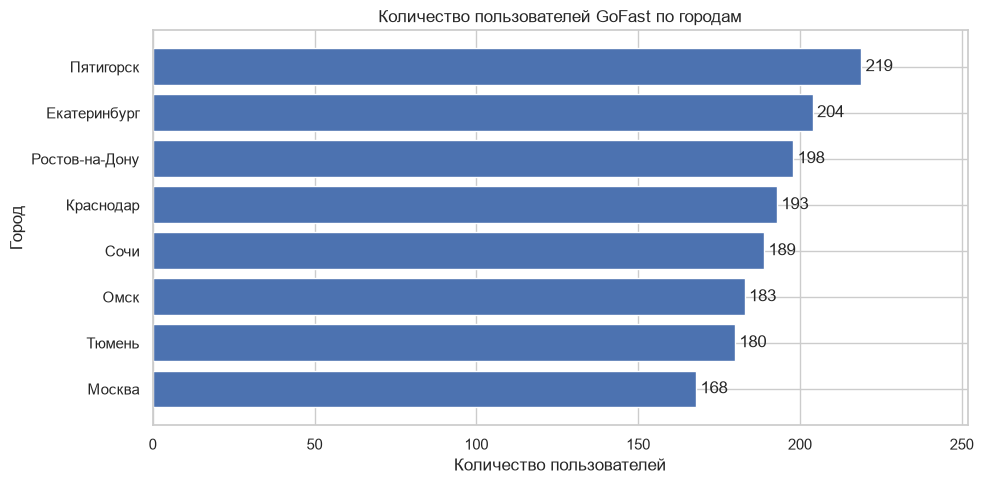

In [10]:
city_counts_plot = users_by_city_count.sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(city_counts_plot.index, city_counts_plot, color='#4C72B0')
plt.bar_label(bars, padding=3)
plt.title('Количество пользователей GoFast по городам')
plt.xlabel('Количество пользователей')
plt.ylabel('Город')
plt.xlim(0, city_counts_plot.max() * 1.15)
plt.tight_layout()
plt.show()


В данных восемь городов. Больше всего пользователей в Пятигорске (219), меньше всего в Москве (168). Разница небольшая, поэтому нельзя сказать, что один из городов сильно преобладает.

### 3.2 Пользователи с подпиской и без неё


In [11]:
subscription_type_count = df_users_go['subscription_type'].value_counts()
subscription_type_share = (
    df_users_go['subscription_type'].value_counts(normalize=True) * 100
).round(1)

pd.DataFrame({
    'users': subscription_type_count,
    'share_pct': subscription_type_share
})


,users,share_pct
subscription_type,,
free,835,54.40
ultra,699,45.60


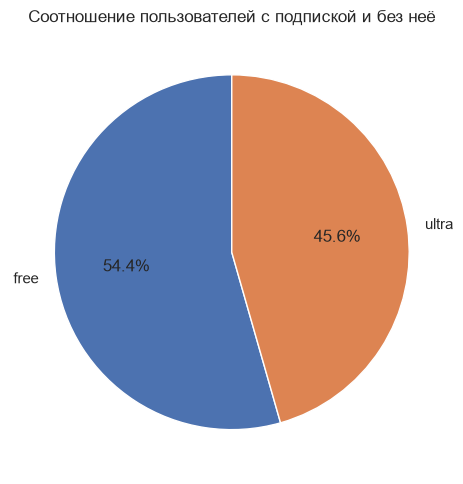

In [12]:
subscription_colors = {'free': '#4C72B0', 'ultra': '#DD8452'}

plt.figure(figsize=(7, 5))
plt.pie(
    subscription_type_count,
    labels=subscription_type_count.index,
    autopct='%.1f%%',
    startangle=90,
    colors=[subscription_colors[item] for item in subscription_type_count.index]
)
plt.title('Соотношение пользователей с подпиской и без неё')
plt.tight_layout()
plt.show()


Тарифом `free` пользуются 835 человек (54,4%), подпиской `ultra` пользуются 699 человек (45,6%). Пользователей без подписки немного больше.

### 3.3 Возраст пользователей


In [13]:
age_description = df_users_go['age'].describe()
n_bins = int(df_users_go['age'].max() - df_users_go['age'].min())

users_under_18 = df_users_go['age'].lt(18).sum()
users_under_18_ratio = users_under_18 / len(df_users_go)

display(age_description)
print(f'Пользователей младше 18 лет: {users_under_18} '
      f'({users_under_18_ratio:.1%})')


count   1,534.00
mean       24.90
std         4.57
min        12.00
25%        22.00
50%        25.00
75%        28.00
max        43.00
Name: age, dtype: float64

Пользователей младше 18 лет: 79 (5.1%)


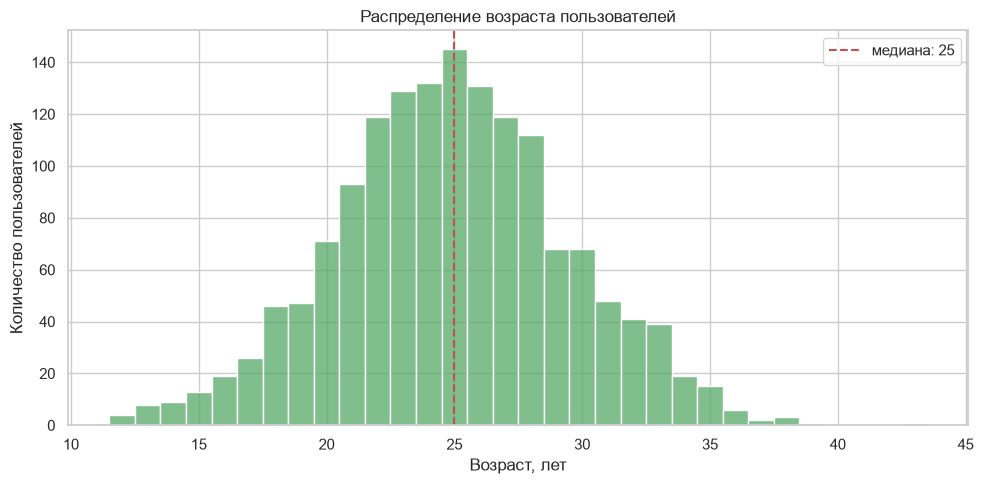

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_users_go,
    x='age',
    bins=n_bins,
    discrete=True,
    color='#55A868'
)
plt.axvline(df_users_go['age'].median(), color='#C44E52', linestyle='--',
            label=f'медиана: {df_users_go["age"].median():.0f}')
plt.title('Распределение возраста пользователей')
plt.xlabel('Возраст, лет')
plt.ylabel('Количество пользователей')
plt.legend()
plt.tight_layout()
plt.show()


Пользователям от 12 до 43 лет. Среднее и медиана составляют около 25 лет. Половина пользователей находится в возрасте от 22 до 28 лет. Доля пользователей младше 18 лет равна 5,1%.

### 3.4 Расстояние одной поездки


In [15]:
distance_description = df_rides_go['distance'].describe()
distance_description


count   18,068.00
mean     3,070.66
std      1,116.83
min          0.86
25%      2,543.23
50%      3,133.61
75%      3,776.22
max      7,211.01
Name: distance, dtype: float64

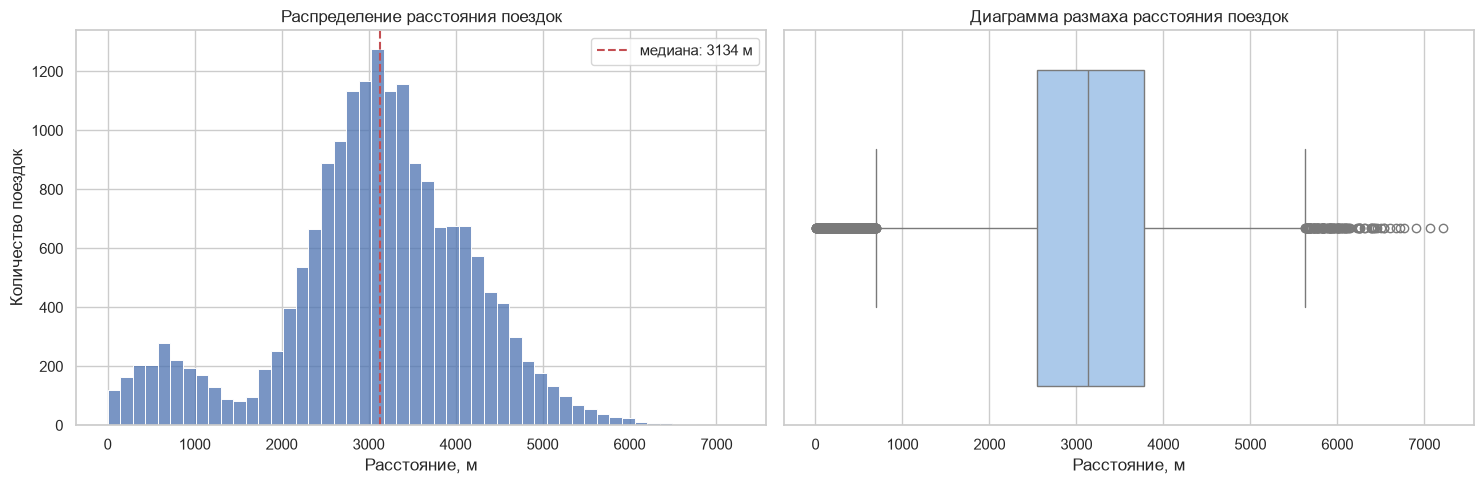

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df_rides_go,
    x='distance',
    bins=50,
    ax=axes[0],
    color='#4C72B0'
)
axes[0].axvline(
    df_rides_go['distance'].median(),
    color='#C44E52', linestyle='--',
    label=f'медиана: {df_rides_go["distance"].median():.0f} м'
)
axes[0].set_title('Распределение расстояния поездок')
axes[0].set_xlabel('Расстояние, м')
axes[0].set_ylabel('Количество поездок')
axes[0].legend()

sns.boxplot(
    data=df_rides_go,
    x='distance',
    ax=axes[1],
    color='#A1C9F4'
)
axes[1].set_title('Диаграмма размаха расстояния поездок')
axes[1].set_xlabel('Расстояние, м')

plt.tight_layout()
plt.show()


Среднее расстояние одной поездки равно 3 071 м, медиана составляет 3 134 м. Половина поездок имеет расстояние от 2 543 до 3 776 м. В данных есть очень короткие поездки и несколько поездок длиннее 7 км. Я не стала их удалять, потому что такие поездки могли быть совершены на самом деле.

### 3.5 Продолжительность поездок


In [17]:
duration_mean = df_rides_go['duration'].mean()
duration_std = df_rides_go['duration'].std()
duration_pct25 = df_rides_go['duration'].quantile(0.25)
duration_pct75 = df_rides_go['duration'].quantile(0.75)
short_rides = df_rides_go['duration'].le(1).sum()

print(f'Средняя длительность: {duration_mean:.2f} мин')
print(f'Стандартное отклонение: {duration_std:.2f} мин')
print(f'Q1: {duration_pct25:.2f} мин')
print(f'Медиана: {df_rides_go["duration"].median():.2f} мин')
print(f'Q3: {duration_pct75:.2f} мин')
print(f'Поездок длительностью до 1 минуты: {short_rides}')


Средняя длительность: 17.81 мин
Стандартное отклонение: 6.09 мин
Q1: 13.60 мин
Медиана: 17.68 мин
Q3: 21.72 мин
Поездок длительностью до 1 минуты: 95


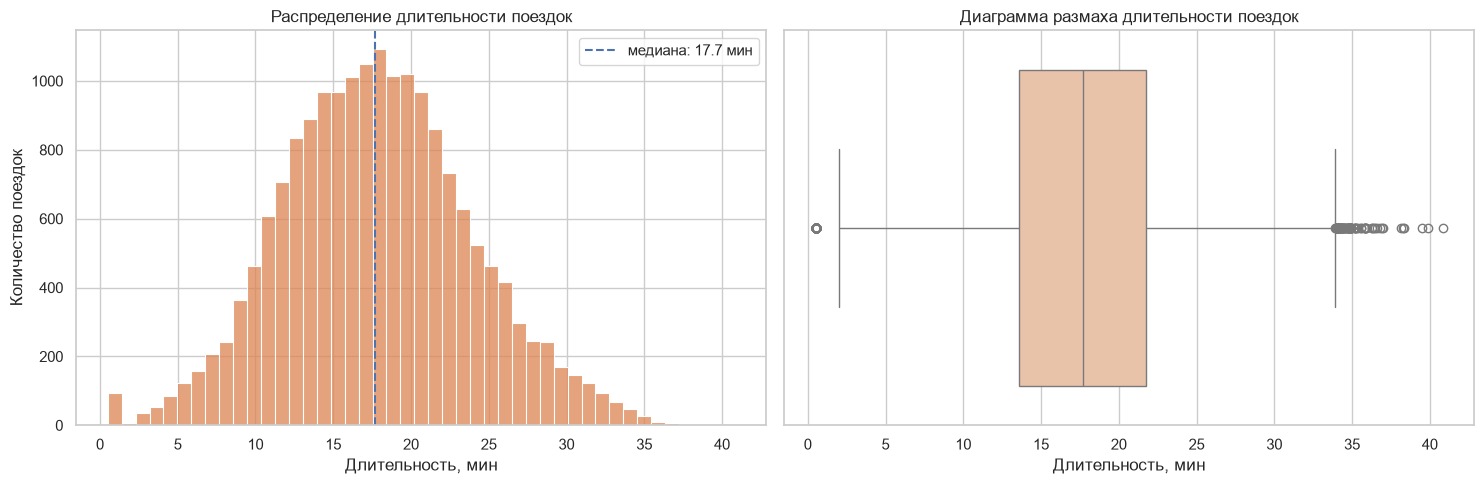

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df_rides_go,
    x='duration',
    bins=45,
    ax=axes[0],
    color='#DD8452'
)
axes[0].axvline(
    df_rides_go['duration'].median(),
    color='#4C72B0', linestyle='--',
    label=f'медиана: {df_rides_go["duration"].median():.1f} мин'
)
axes[0].set_title('Распределение длительности поездок')
axes[0].set_xlabel('Длительность, мин')
axes[0].set_ylabel('Количество поездок')
axes[0].legend()

sns.boxplot(
    data=df_rides_go,
    x='duration',
    ax=axes[1],
    color='#F2C1A0'
)
axes[1].set_title('Диаграмма размаха длительности поездок')
axes[1].set_xlabel('Длительность, мин')

plt.tight_layout()
plt.show()


Средняя длительность поездки равна 17,81 минуты, медиана составляет 17,68 минуты. Половина поездок длится от 13,60 до 21,72 минуты.

Отдельно я посмотрела поездки не длиннее одной минуты. Такой порог выбран для проверки очень коротких сессий, которые могли закончиться сразу после старта. Их оказалось 95. Я оставила эти строки, поскольку длительность может быть реальной, отрицательных значений нет, а другой информации об этих поездках у нас нет.

### Вывод по шагу 3

Пользователей без подписки немного больше. Чаще всего сервисом пользуются люди в возрасте от 22 до 28 лет. Обычная поездка длится около 18 минут, её расстояние составляет примерно 3,1 км. Необычно короткие и длинные поездки оставлены в данных.


## Шаг 4. Объединение данных

### 4.1 Общий датафрейм

К таблице поездок добавлю данные о пользователях и тарифах. После объединения проверю число строк и пропуски.


In [19]:
df = (
    df_rides_go.merge(
        df_users_go,
        on='user_id',
        how='left',
        validate='many_to_one'
    )
    .merge(
        df_subscriptions_go,
        on='subscription_type',
        how='left',
        validate='many_to_one'
    )
)

n_rows, n_cols = df.shape
display(df.head())
print(f'В объединённом датафрейме {n_rows:,} строк и {n_cols} столбцов')
print(f'Пропущенных значений: {df.isna().sum().sum()}')
print(f'Число строк совпадает с таблицей поездок: '
      f'{len(df) == initial_ride_rows}')


,user_id,distance,duration,date,month,duration_rounded,name,age,city,subscription_type,minute_price,start_ride_price,subscription_fee
0,1,"4,409.92",25.60,2021-01-01,1,26,Кира,22,Тюмень,ultra,6,0,199
1,1,"2,617.59",15.82,2021-01-18,1,16,Кира,22,Тюмень,ultra,6,0,199
2,1,754.16,6.23,2021-04-20,4,7,Кира,22,Тюмень,ultra,6,0,199
3,1,"2,694.78",18.51,2021-08-11,8,19,Кира,22,Тюмень,ultra,6,0,199
4,1,"4,028.69",26.27,2021-08-28,8,27,Кира,22,Тюмень,ultra,6,0,199


В объединённом датафрейме 18,068 строк и 13 столбцов
Пропущенных значений: 0
Число строк совпадает с таблицей поездок: True


После объединения осталось 18 068 строк, то есть все поездки сохранились. Новых пропусков нет.

### 4.2 Пользователи `free` и `ultra`


In [20]:
df_ultra = df.loc[df['subscription_type'].eq('ultra')].copy()
df_free = df.loc[df['subscription_type'].eq('free')].copy()

subscription_ride_stats = (
    df.groupby('subscription_type')
      .agg(
          rides=('user_id', 'size'),
          distance_mean=('distance', 'mean'),
          distance_median=('distance', 'median'),
          duration_mean=('duration', 'mean'),
          duration_median=('duration', 'median')
      )
)
subscription_ride_stats.round(2)


,rides,distance_mean,distance_median,duration_mean,duration_median
subscription_type,,,,,
free,11568,"3,045.50","3,114.65",17.39,17.33
ultra,6500,"3,115.45","3,148.64",18.54,18.18


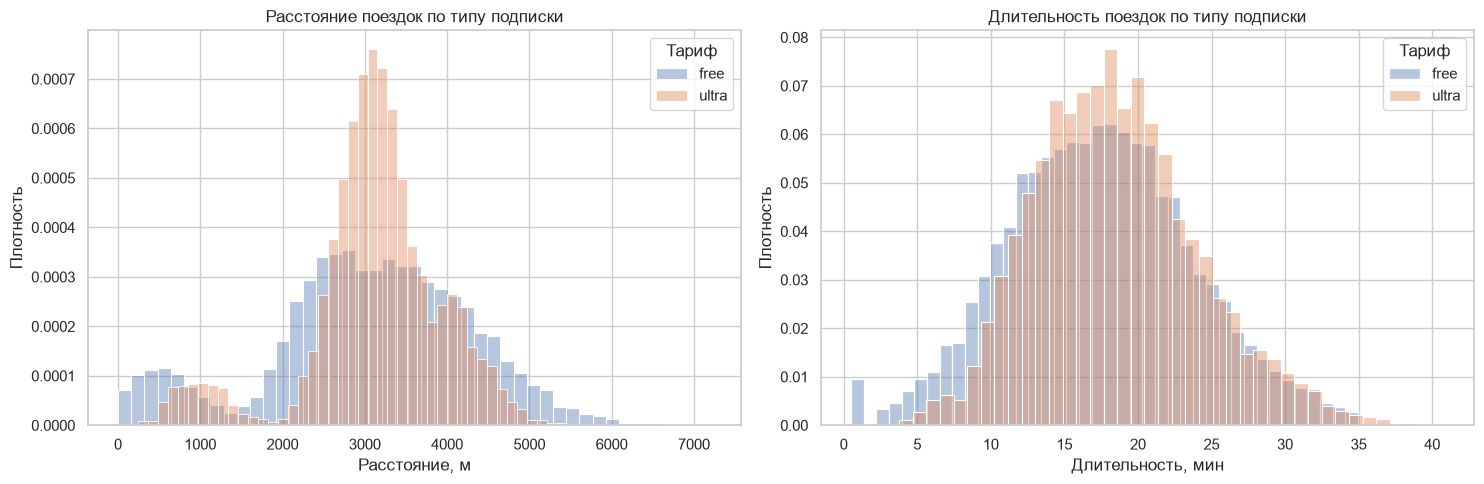

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for subscription, data in [('free', df_free), ('ultra', df_ultra)]:
    sns.histplot(
        data=data,
        x='distance',
        bins=45,
        stat='density',
        alpha=0.4,
        label=subscription,
        color=subscription_colors[subscription],
        ax=axes[0]
    )
    sns.histplot(
        data=data,
        x='duration',
        bins=40,
        stat='density',
        alpha=0.4,
        label=subscription,
        color=subscription_colors[subscription],
        ax=axes[1]
    )

axes[0].set_title('Расстояние поездок по типу подписки')
axes[0].set_xlabel('Расстояние, м')
axes[0].set_ylabel('Плотность')
axes[0].legend(title='Тариф')

axes[1].set_title('Длительность поездок по типу подписки')
axes[1].set_xlabel('Длительность, мин')
axes[1].set_ylabel('Плотность')
axes[1].legend(title='Тариф')

plt.tight_layout()
plt.show()


Среднее расстояние поездки у подписчиков составляет 3 115 м, у пользователей `free` 3 045 м. Средняя длительность равна 18,54 и 17,39 минуты соответственно. Разница небольшая, а распределения заметно пересекаются. Поэтому разницу в длительности дополнительно проверю статистическим тестом.

### Вывод по шагу 4

Данные объединились без потерь. Получилось 6 500 поездок пользователей `ultra` и 11 568 поездок пользователей `free`. По средним значениям подписчики ездят немного дольше, но для окончательного вывода нужен статистический тест.


## Шаг 5. Подсчёт выручки

Сгруппирую данные по пользователю, имени, тарифу и месяцу. Для каждого пользователя посчитаю расстояние, число поездок и общее округлённое время за месяц.


In [22]:
df_gp = df.groupby(
    ['user_id', 'name', 'subscription_type', 'month'],
    as_index=False
)

df_agg = df_gp.agg(
    total_distance=('distance', 'sum'),
    rides_count=('distance', 'size'),
    total_duration=('duration_rounded', 'sum'),
    minute_price=('minute_price', 'first'),
    start_ride_price=('start_ride_price', 'first'),
    subscription_fee=('subscription_fee', 'first')
)

df_agg.head()


,user_id,name,subscription_type,month,total_distance,rides_count,total_duration,minute_price,start_ride_price,subscription_fee
0,1,Кира,ultra,1,"7,027.51",2,42,6,0,199
1,1,Кира,ultra,4,754.16,1,7,6,0,199
2,1,Кира,ultra,8,"6,723.47",2,46,6,0,199
3,1,Кира,ultra,10,"5,809.91",2,32,6,0,199
4,1,Кира,ultra,11,"7,003.50",3,56,6,0,199


In [23]:
df_agg['monthly_revenue'] = (
    df_agg['start_ride_price'] * df_agg['rides_count']
    + df_agg['minute_price'] * df_agg['total_duration']
    + df_agg['subscription_fee']
)

revenue_summary = (
    df_agg.groupby('subscription_type')['monthly_revenue']
      .agg(['count', 'mean', 'median', 'sum'])
)
revenue_summary.round(2)


,count,mean,median,sum
subscription_type,,,,
free,6798,328.64,274.00,2234104
ultra,4533,362.79,337.00,1644537


In [24]:
coolest_user = (
    df_agg.groupby(['user_id', 'name'])['monthly_revenue']
      .sum()
      .sort_values(ascending=False)
      .head(1)
)
top_user_id = coolest_user.index[0][0]

print('Пользователь с максимальной суммарной выручкой:')
display(coolest_user.to_frame('total_revenue'))
display(
    df_agg.loc[
        df_agg['user_id'].eq(top_user_id),
        ['user_id', 'name', 'month', 'rides_count', 'monthly_revenue']
    ].sort_values('month')
)


Пользователь с максимальной суммарной выручкой:


,,total_revenue
user_id,name,
1236,Александр,5022


,user_id,name,month,rides_count,monthly_revenue
8877,1236,Александр,1,2,236
8878,1236,Александр,2,3,622
8879,1236,Александр,3,5,786
8880,1236,Александр,4,1,210
8881,1236,Александр,5,3,590
8882,1236,Александр,6,1,282
8883,1236,Александр,7,1,290
8884,1236,Александр,8,2,460
8885,1236,Александр,9,1,122
8886,1236,Александр,10,3,446


Средняя выручка за пользовательский месяц составляет 362,79 рубля для `ultra` и 328,64 рубля для `free`. Медианы равны 337 и 274 рубля. Общая выручка тарифа `free` выше, так как таких пользователей и активных месяцев больше. Разницу средних проверю в следующем разделе.

### Вывод по шагу 5

После группировки получилось 11 331 строка. Каждая строка соответствует одному пользователю в одном месяце. При расчёте выручки длительность каждой поездки округлялась вверх до целой минуты. Пока подписка выглядит выгоднее по средней месячной выручке, но это ещё нужно проверить статистически.


## Шаг 6. Проверка гипотез

Уровень статистической значимости для всех тестов равен 0,05. Для сравнения групп использую односторонний t-тест Уэлча с параметром `equal_var=False`, так как дисперсии групп могут отличаться.


In [25]:
alpha = 0.05


def print_stattest_results(p_value, alpha=0.05):
    print(f'p-value = {p_value:.6g}')
    if p_value < alpha:
        print('Отвергаем нулевую гипотезу.')
    else:
        print('Не удалось отвергнуть нулевую гипотезу.')


### 6.1 Тратят ли подписчики больше времени на поездки?

- **H₀:** средняя длительность поездки у пользователей `ultra` не больше, чем у пользователей `free`.
- **H₁:** средняя длительность поездки у пользователей `ultra` больше, чем у пользователей `free`.


In [26]:
ultra_duration = df_ultra['duration']
free_duration = df_free['duration']

duration_test = st.ttest_ind(
    ultra_duration,
    free_duration,
    equal_var=False,
    alternative='greater'
)

print(f'Среднее ultra: {ultra_duration.mean():.2f} мин')
print(f'Среднее free: {free_duration.mean():.2f} мин')
print_stattest_results(duration_test.pvalue, alpha)


Среднее ultra: 18.54 мин
Среднее free: 17.39 мин
p-value = 5.67578e-37
Отвергаем нулевую гипотезу.


Значение `p-value` намного меньше 0,05, поэтому нулевая гипотеза отвергается. Средняя длительность поездки у пользователей `ultra` равна 18,54 минуты, у пользователей `free` 17,39 минуты. Подписчики действительно ездят дольше.

### 6.2 Превышает ли средняя дистанция подписчиков 3 130 метров?

Расстояние 3 130 м считается оптимальным с точки зрения износа самоката.

- **H₀:** среднее расстояние поездки подписчиков не превышает 3 130 м.
- **H₁:** среднее расстояние поездки подписчиков превышает 3 130 м.


In [27]:
null_hypothesis = 3130
ultra_distance = df_ultra['distance']

distance_test = st.ttest_1samp(
    ultra_distance,
    null_hypothesis,
    alternative='greater'
)

print(f'Средняя дистанция ultra: {ultra_distance.mean():.2f} м')
print_stattest_results(distance_test.pvalue, alpha)


Средняя дистанция ultra: 3115.45 м
p-value = 0.919537
Не удалось отвергнуть нулевую гипотезу.


Получено `p-value ≈ 0,920`, поэтому нулевая гипотеза не отвергается. Среднее по выборке равно 3 115 м, что ниже 3 130 м. Данные не позволяют утверждать, что среднее расстояние поездки подписчиков превышает оптимальное. При этом отдельные поездки могут быть длиннее 3 130 м.

### 6.3 Выше ли помесячная выручка от подписчиков?

- **H₀:** средняя помесячная выручка от `ultra` не больше, чем от `free`.
- **H₁:** средняя помесячная выручка от `ultra` больше, чем от `free`.


In [28]:
revenue_ultra = df_agg.loc[
    df_agg['subscription_type'].eq('ultra'), 'monthly_revenue'
]
revenue_free = df_agg.loc[
    df_agg['subscription_type'].eq('free'), 'monthly_revenue'
]

revenue_test = st.ttest_ind(
    revenue_ultra,
    revenue_free,
    equal_var=False,
    alternative='greater'
)

print(f'Средняя выручка ultra: {revenue_ultra.mean():.2f} руб.')
print(f'Средняя выручка free: {revenue_free.mean():.2f} руб.')
print_stattest_results(revenue_test.pvalue, alpha)


Средняя выручка ultra: 362.79 руб.
Средняя выручка free: 328.64 руб.
p-value = 8.87414e-40
Отвергаем нулевую гипотезу.


Нулевая гипотеза отвергается. Средняя помесячная выручка составляет 362,79 рубля у `ultra` и 328,64 рубля у `free`. Разница статистически значима.

### Вывод по шагу 6

Пользователи `ultra` в среднем ездят дольше и приносят больше выручки за активный месяц. Подтверждения того, что их среднее расстояние превышает 3 130 м, не получено. При этом в расчёте месячной выручки один пользователь может встречаться несколько раз, если он совершал поездки в разные месяцы. Ниже я отдельно проверю результат после группировки по пользователям.


#### Проверка результата по пользователям

В предыдущем тесте у одного пользователя может быть до 12 строк. Чтобы убрать повторения, соберу данные до одной строки на пользователя. Сравню общую выручку за год и среднюю выручку за активный месяц. Второй показатель ближе к исходной гипотезе, поскольку она относится именно к помесячной выручке.


In [29]:
revenue_by_user = (
    df_agg.groupby(['user_id', 'subscription_type'], as_index=False)
          .agg(
              annual_revenue=('monthly_revenue', 'sum'),
              mean_active_month_revenue=('monthly_revenue', 'mean'),
              active_months=('month', 'nunique')
          )
)

annual_ultra = revenue_by_user.loc[
    revenue_by_user['subscription_type'].eq('ultra'), 'annual_revenue'
]
annual_free = revenue_by_user.loc[
    revenue_by_user['subscription_type'].eq('free'), 'annual_revenue'
]
annual_test = st.ttest_ind(
    annual_ultra, annual_free, equal_var=False, alternative='greater'
)

mean_month_ultra = revenue_by_user.loc[
    revenue_by_user['subscription_type'].eq('ultra'),
    'mean_active_month_revenue'
]
mean_month_free = revenue_by_user.loc[
    revenue_by_user['subscription_type'].eq('free'),
    'mean_active_month_revenue'
]
mean_month_test = st.ttest_ind(
    mean_month_ultra, mean_month_free,
    equal_var=False, alternative='greater'
)

user_revenue_check = (
    revenue_by_user.groupby('subscription_type')
                   .agg(
                       users=('user_id', 'size'),
                       mean_total_revenue=('annual_revenue', 'mean'),
                       mean_active_month_revenue=(
                           'mean_active_month_revenue', 'mean'
                       ),
                       mean_active_months=('active_months', 'mean')
                   )
)
display(user_revenue_check.round(2))
print(f'p-value для суммарной выручки: {annual_test.pvalue:.6g}')
print(
    'p-value для средней выручки за активный месяц: '
    f'{mean_month_test.pvalue:.6g}'
)


,users,mean_total_revenue,mean_active_month_revenue,mean_active_months
subscription_type,,,,
free,835,"2,675.57",328.52,8.14
ultra,699,"2,352.70",363.07,6.48


p-value для суммарной выручки: 1
p-value для средней выручки за активный месяц: 4.44335e-37


По общей выручке за год преимущество `ultra` не подтвердилось. Среднее значение составляет 2 353 рубля для `ultra` и 2 676 рублей для `free`, односторонний `p-value` равен 1. У пользователей `free` больше активных месяцев: в среднем 8,14 против 6,48.

Если сравнивать среднюю выручку за активный месяц, результат сохраняется. У `ultra` она равна 363,07 рубля, у `free` 328,52 рубля. Значение `p-value` меньше 0,001. Получается, что подписчики приносят больше выручки за активный месяц, но не за весь год.


## Шаг 7. Моделирование распределений

### 7.1 Длительность поездок подписчиков

Скидка предназначена для подписчиков, поэтому среднее и стандартное отклонение рассчитаю по поездкам пользователей `ultra`. Для моделирования использую исходную длительность без округления.


In [30]:
mu = df_ultra['duration'].mean()
sigma = df_ultra['duration'].std()
target_time = 30
duration_norm_dist = st.norm(loc=mu, scale=sigma)

prob = 1 - duration_norm_dist.cdf(target_time)

print(f'Средняя длительность: {mu:.2f} мин')
print(f'Стандартное отклонение: {sigma:.2f} мин')
print(f'Вероятность поездки более 30 минут: {prob:.2%}')


Средняя длительность: 18.54 мин
Стандартное отклонение: 5.57 мин
Вероятность поездки более 30 минут: 1.99%


In [31]:
low = 20
high = 30
prob_interval = (
    duration_norm_dist.cdf(high) - duration_norm_dist.cdf(low)
)

print(f'Вероятность поездки от 20 до 30 минут: {prob_interval:.2%}')


Вероятность поездки от 20 до 30 минут: 37.69%


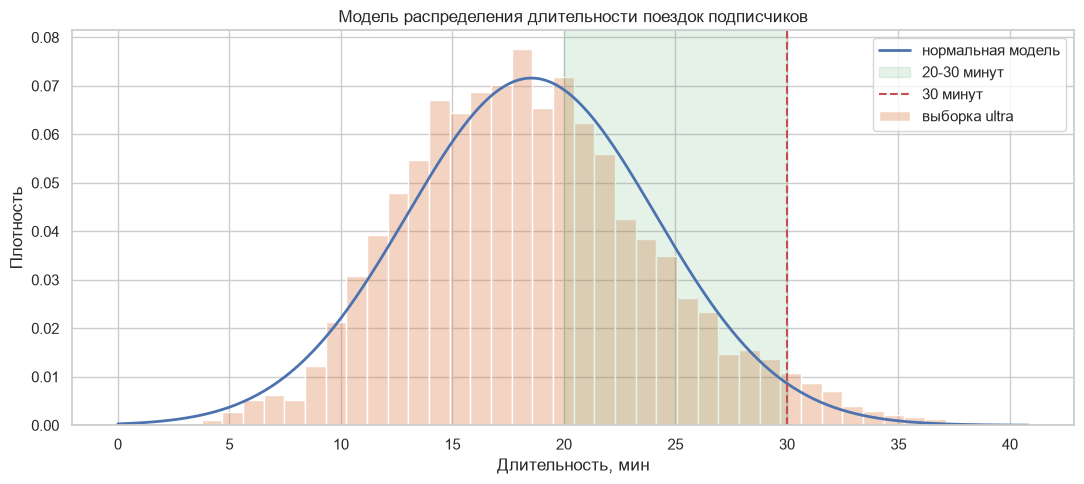

In [32]:
x_duration = np.linspace(
    max(0, mu - 4 * sigma),
    mu + 4 * sigma,
    400
)

plt.figure(figsize=(11, 5))
sns.histplot(
    df_ultra['duration'],
    bins=40,
    stat='density',
    color='#DD8452',
    alpha=0.35,
    label='выборка ultra'
)
plt.plot(
    x_duration,
    duration_norm_dist.pdf(x_duration),
    color='#4C72B0',
    linewidth=2,
    label='нормальная модель'
)
plt.axvspan(20, 30, color='#55A868', alpha=0.15, label='20-30 минут')
plt.axvline(30, color='#C44E52', linestyle='--', label='30 минут')
plt.title('Модель распределения длительности поездок подписчиков')
plt.xlabel('Длительность, мин')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()


По нормальной модели около 1,99% поездок подписчиков длятся больше 30 минут. Это небольшая доля. В интервал от 20 до 30 минут попадает около 37,69% поездок, поэтому такая акция охватит намного больше поездок.

### 7.2 Критическая дистанция

Найду 90-й процентиль нормального распределения расстояния. Полученную границу должны превышать только 10% поездок.


In [33]:
mu_distance = df['distance'].mean()
sigma_distance = df['distance'].std()
target_prob = 0.90
distance_norm = st.norm(loc=mu_distance, scale=sigma_distance)
value = distance_norm.ppf(target_prob)
empirical_q90 = df['distance'].quantile(target_prob)

print(f'Среднее расстояние: {mu_distance:.2f} м')
print(f'Стандартное отклонение: {sigma_distance:.2f} м')
print(f'90-й процентиль нормальной модели: {value:.2f} м')
print(f'Эмпирический 90-й процентиль: {empirical_q90:.2f} м')


Среднее расстояние: 3070.66 м
Стандартное отклонение: 1116.83 м
90-й процентиль нормальной модели: 4501.94 м
Эмпирический 90-й процентиль: 4392.13 м


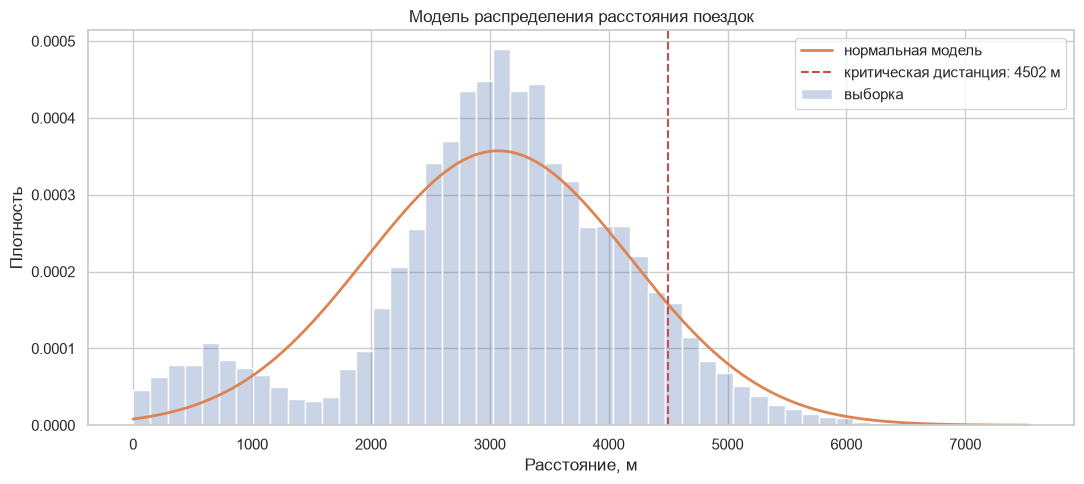

In [34]:
x_distance = np.linspace(
    max(0, mu_distance - 4 * sigma_distance),
    mu_distance + 4 * sigma_distance,
    500
)

plt.figure(figsize=(11, 5))
sns.histplot(
    df['distance'],
    bins=50,
    stat='density',
    color='#4C72B0',
    alpha=0.3,
    label='выборка'
)
plt.plot(
    x_distance,
    distance_norm.pdf(x_distance),
    color='#DD8452',
    linewidth=2,
    label='нормальная модель'
)
plt.axvline(
    value,
    color='#C44E52',
    linestyle='--',
    label=f'критическая дистанция: {value:.0f} м'
)
plt.title('Модель распределения расстояния поездок')
plt.xlabel('Расстояние, м')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()


По нормальной модели 90-й процентиль равен 4 502 м. Эмпирический 90-й процентиль немного ниже и составляет 4 392 м. В качестве примерной границы можно использовать 4,5 км. Перед введением доплаты нужно отдельно проверить, как расстояние связано с износом самоката и как новая плата повлияет на пользователей.

### Вывод по шагу 7

Поездки длиннее 30 минут составляют около 2% поездок `ultra`. В интервал от 20 до 30 минут попадает около 38%, поэтому этот вариант акции охватит больше поездок. Граница для 10% самых длинных поездок составляет примерно 4,5 км. Расчёты основаны на нормальной модели, поэтому результат является приблизительным.


## Итоговый вывод и рекомендации

### Что было сделано

Я изучила данные о пользователях, поездках и тарифах GoFast. В ходе предобработки преобразовала даты, добавила номер месяца, удалила 31 дубль пользователей и округлила длительность поездок для расчёта выручки. После этого сравнила пользователей двух тарифов, рассчитала выручку и проверила три гипотезы.

### Основные результаты

- В данных осталось 1 534 пользователя и 18 068 поездок за 2021 год.
- Тарифом `free` пользуются 54,4% пользователей, подпиской `ultra` 45,6%.
- Средний возраст пользователя составляет около 25 лет.
- Обычная поездка длится примерно 18 минут, её расстояние составляет около 3,1 км.
- Пользователи `ultra` ездят дольше: 18,54 минуты против 17,39 минуты.
- Среднее расстояние поездки подписчиков не превышает ориентир 3 130 м.
- Средняя выручка за активный месяц выше у `ultra`: около 363 рублей против 329 рублей.
- Общая выручка за год выше у `free`. В этой группе больше активных месяцев на пользователя.
- Около 2% поездок подписчиков длятся больше 30 минут. На интервал от 20 до 30 минут приходится около 37,7% поездок.
- Расстояние около 4,5 км превышают примерно 10% поездок.

### Рекомендации

1. Можно протестировать продвижение `ultra`, поскольку подписчики приносят больше выручки за активный месяц. Одновременно стоит разобраться, почему у них меньше активных месяцев.
2. Для акции лучше взять поездки длительностью от 20 до 30 минут. Так предложение увидит больше пользователей, чем при пороге в 30 минут.
3. Значение 4,5 км можно использовать как предварительный порог для дополнительной платы. До запуска нужно проверить связь расстояния с износом и возможную реакцию пользователей.
4. Продвижение подписки лучше сначала проверить с помощью A/B-теста. В тесте стоит оценивать выручку, конверсию в подписку, удержание, число активных месяцев и расходы на обслуживание.

### Ограничения

Нормальное распределение используется как приближение. Оно не учитывает сезонность, города и повторные поездки одних пользователей. В основном тесте месячной выручки один пользователь мог встречаться несколько раз, поэтому я также провела проверку по одной строке на пользователя. Преимущество `ultra` сохранилось для выручки за активный месяц, но не для общей суммы за год.
